In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score



print("All libraries imported successfully!")

All libraries imported successfully!


In [20]:
df=pd.read_csv(r"Train.csv")

In [56]:
df.head(8)

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.300,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.920,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.500,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.200,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.930,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052
5,FDP36,10.395,Regular,0.000000,Baking Goods,51.4008,OUT018,2009,Medium,Tier 3,Supermarket Type2,556.6088
6,FDO10,13.650,Regular,0.012741,Snack Foods,57.6588,OUT013,1987,High,Tier 3,Supermarket Type1,343.5528
7,FDP10,NaN,Low Fat,0.127470,Snack Foods,107.7622,OUT027,1985,Medium,Tier 3,Supermarket Type3,4022.7636


In [21]:

# MANUAL NORMAL EQUATION CALCULATION

# Select 8 actual observations with no missing values
manual_data = df[
    ['Item_MRP', 'Item_Visibility', 'Item_Outlet_Sales']
].dropna().sample(n=8, random_state=42)

# Independent variables
X_manual = manual_data[
    ['Item_MRP', 'Item_Visibility']
].values

# Add intercept column (1s)
X_manual = np.column_stack([
    np.ones(len(X_manual)),
    X_manual
])

# Dependent variable
y_manual = manual_data[
    'Item_Outlet_Sales'
].values.reshape(-1, 1)

# Normal equation using pseudoinverse
beta = np.linalg.pinv(X_manual.T @ X_manual) @ X_manual.T @ y_manual

# Display selected observations
print("Selected 8 Observations:")
display(manual_data)

# Display coefficients
print("\nRegression Coefficients:")
print("Intercept (b0):", beta[0][0])
print("Item_MRP coefficient (b1):", beta[1][0])
print("Item_Visibility coefficient (b2):", beta[2][0])

# Calculate predictions for these 8 observations
manual_predictions = X_manual @ beta

print("\nManual Predictions:")
print(manual_predictions.flatten())


Selected 8 Observations:


,Item_MRP,Item_Visibility,Item_Outlet_Sales
7503,79.4302,0.026300,1743.0644
2957,42.7086,0.071136,356.8688
7031,42.0454,0.041313,377.5086
1084,173.7054,0.044767,5778.4782
856,197.5110,0.012456,2356.9320
4304,32.4900,0.041951,865.5400
2132,209.0270,0.126832,4613.9940
1385,142.0154,0.013551,2410.8618



Regression Coefficients:
Intercept (b0): -527.3817033881264
Item_MRP coefficient (b1): 21.326465224838557
Item_Visibility coefficient (b2): 8259.729509296918

Manual Predictions:
[1383.81290408  971.00481392  710.53393952 3546.90404433 3787.71120108
  512.02269043 4978.02215037 2613.23605626]


In [22]:
df.shape

(8523, 12)

In [23]:
df.isnull().sum()

,0
Item_Identifier,0
Item_Weight,1463
Item_Fat_Content,0
Item_Visibility,0
Item_Type,0
Item_MRP,0
Outlet_Identifier,0
Outlet_Establishment_Year,0
Outlet_Size,2410
Outlet_Location_Type,0


In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [25]:
df.describe()

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,7060.000000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.857645,0.066132,140.992782,1997.831867,2181.288914
std,4.643456,0.051598,62.275067,8.371760,1706.499616
min,4.555000,0.000000,31.290000,1985.000000,33.290000
25%,8.773750,0.026989,93.826500,1987.000000,834.247400
50%,12.600000,0.053931,143.012800,1999.000000,1794.331000
75%,16.850000,0.094585,185.643700,2004.000000,3101.296400
max,21.350000,0.328391,266.888400,2009.000000,13086.964800


In [26]:
print("Total Duplicate Records:", df.duplicated().sum())

Total Duplicate Records: 0


In [27]:
if 'Item_Fat_Content' in df.columns:
    df['Item_Fat_Content'] = df['Item_Fat_Content'].replace({
        'LF': 'Low Fat',
        'low fat': 'Low Fat',
        'reg': 'Regular'
    })

print(df['Item_Fat_Content'].value_counts(dropna=False))

Item_Fat_Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64


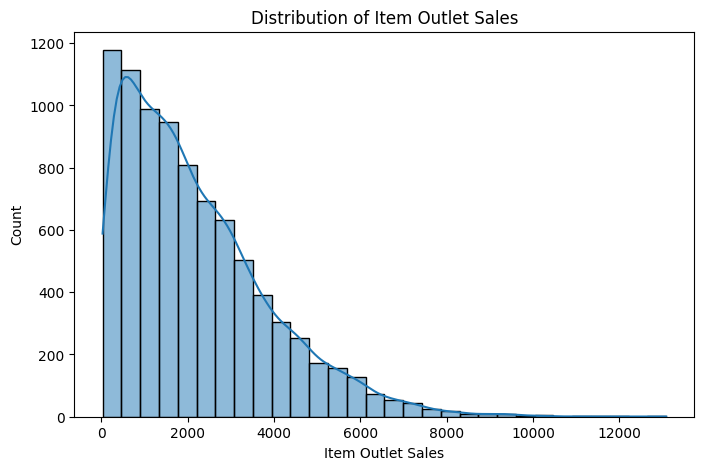

In [28]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Item_Outlet_Sales', bins=30, kde=True)
plt.title('Distribution of Item Outlet Sales')
plt.xlabel('Item Outlet Sales')
plt.show()

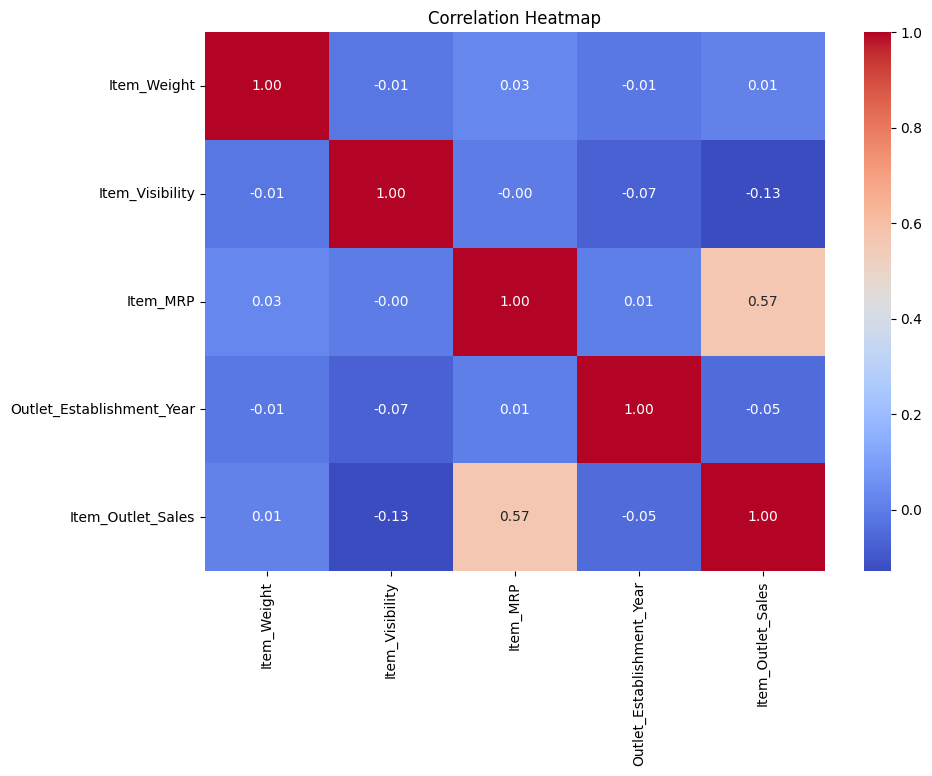

In [29]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

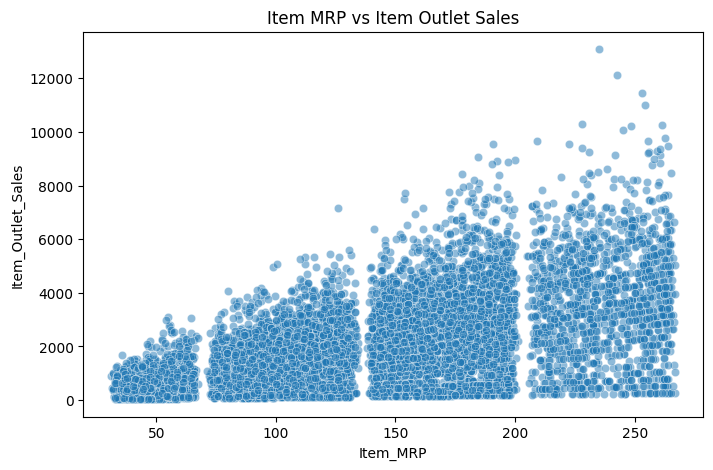

In [30]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Item_MRP', y='Item_Outlet_Sales', alpha=0.5)
plt.title('Item MRP vs Item Outlet Sales')
plt.show()

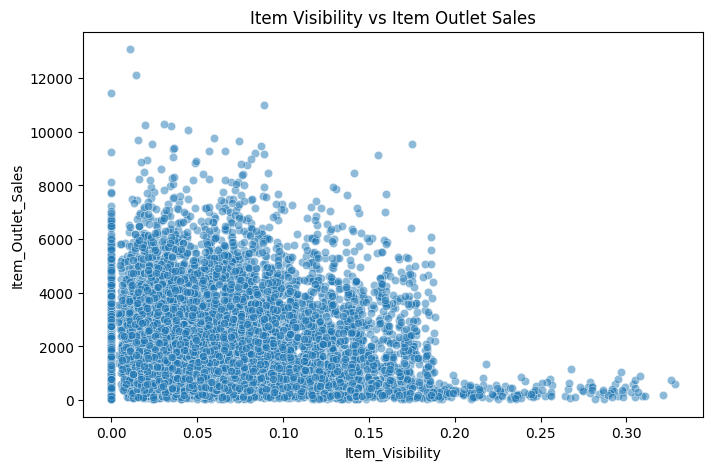

In [31]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Item_Visibility', y='Item_Outlet_Sales', alpha=0.5)
plt.title('Item Visibility vs Item Outlet Sales')
plt.show()

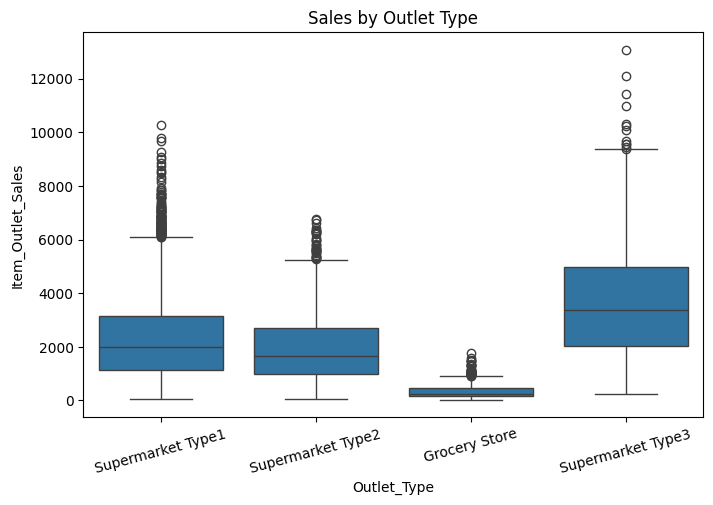

In [32]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Outlet_Type', y='Item_Outlet_Sales')
plt.title('Sales by Outlet Type')
plt.xticks(rotation=15)
plt.show()

In [33]:
print("Correlation of numerical features with target:")
print(numeric_df.corr()['Item_Outlet_Sales'].sort_values(ascending=False))

Correlation of numerical features with target:
Item_Outlet_Sales            1.000000
Item_MRP                     0.567574
Item_Weight                  0.014123
Outlet_Establishment_Year   -0.049135
Item_Visibility             -0.128625
Name: Item_Outlet_Sales, dtype: float64


In [34]:
target = 'Item_Outlet_Sales'
X = df.drop(columns=[target, 'Item_Identifier'], errors='ignore')
y = df[target]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Features:", X.columns.tolist())

X shape: (8523, 10)
y shape: (8523,)
Features: ['Item_Weight', 'Item_Fat_Content', 'Item_Visibility', 'Item_Type', 'Item_MRP', 'Outlet_Identifier', 'Outlet_Establishment_Year', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type']


In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 6818
Testing rows: 1705


In [42]:

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Select numerical features from training data
X_vif = X_train[numeric_features].copy()

# Handle missing values
X_vif = X_vif.fillna(X_vif.median())

# Add constant
X_vif = add_constant(X_vif)

# Calculate VIF
vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

# Remove intercept from displayed results
vif_data = vif_data[vif_data["Feature"] != "const"]

display(vif_data.sort_values("VIF", ascending=False))


,Feature,VIF
2,Item_Visibility,1.005403
4,Outlet_Establishment_Year,1.005391
1,Item_Weight,1.000813
3,Item_MRP,1.000566


In [45]:
# Import required libraries
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression

# Separate numerical and categorical features
numeric_features = X.select_dtypes(include=['number']).columns.tolist()
categorical_features = X.select_dtypes(exclude=['number']).columns.tolist()

print("Imports and feature selection completed!")

Imports and feature selection completed!


In [46]:
numeric_features = X.select_dtypes(include=['number']).columns.tolist()
categorical_features = X.select_dtypes(exclude=['number']).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

model.fit(X_train, y_train)
print("Multiple Linear Regression model trained.")

Multiple Linear Regression model trained.


In [47]:
from sklearn.metrics import r2_score

# Predict test data
y_pred = model.predict(X_test)

# Calculate R2
r2 = r2_score(y_test, y_pred)

# Number of observations
n = len(y_test)

# Number of features after preprocessing
p = model.named_steps['preprocessor'].transform(X_test).shape[1]

# Adjusted R2
adjusted_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))

print("R2 Score:", r2)
print("Adjusted R2 Score:", adjusted_r2)

R2 Score: 0.579266098006827
Adjusted R2 Score: 0.5686338333355194


In [48]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

n = len(y_test)
p = X_train.shape[1]
adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print("MULTIPLE LINEAR REGRESSION RESULTS")
print("----------------------------------")
print(f"MAE: {mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R-squared: {r2:.4f}")
print(f"Adjusted R-squared (approx., using original feature count): {adjusted_r2:.4f}")

MULTIPLE LINEAR REGRESSION RESULTS
----------------------------------
MAE: 792.02
MSE: 1143542.15
RMSE: 1069.37
R-squared: 0.5793
Adjusted R-squared (approx., using original feature count): 0.5768


In [49]:
single_model = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('regressor', LinearRegression())
])

X_train_single = X_train[['Item_MRP']]
X_test_single = X_test[['Item_MRP']]

single_model.fit(X_train_single, y_train)
y_pred_single = single_model.predict(X_test_single)

single_r2 = r2_score(y_test, y_pred_single)
single_mae = mean_absolute_error(y_test, y_pred_single)
single_rmse = np.sqrt(mean_squared_error(y_test, y_pred_single))

print("SINGLE FEATURE MODEL")
print("--------------------")
print(f"Intercept: {single_model.named_steps['regressor'].intercept_:.2f}")
print(f"Item_MRP coefficient: {single_model.named_steps['regressor'].coef_[0]:.2f}")
print(f"MAE: {single_mae:.2f}")
print(f"RMSE: {single_rmse:.2f}")
print(f"R-squared: {single_r2:.4f}")

print("\nMODEL COMPARISON")
print("----------------")
print(f"Single-feature R2: {single_r2:.4f}")
print(f"Multiple-feature R2: {r2:.4f}")

SINGLE FEATURE MODEL
--------------------
Intercept: -3.62
Item_MRP coefficient: 15.55
MAE: 991.47
RMSE: 1348.41
R-squared: 0.3310

MODEL COMPARISON
----------------
Single-feature R2: 0.3310
Multiple-feature R2: 0.5793


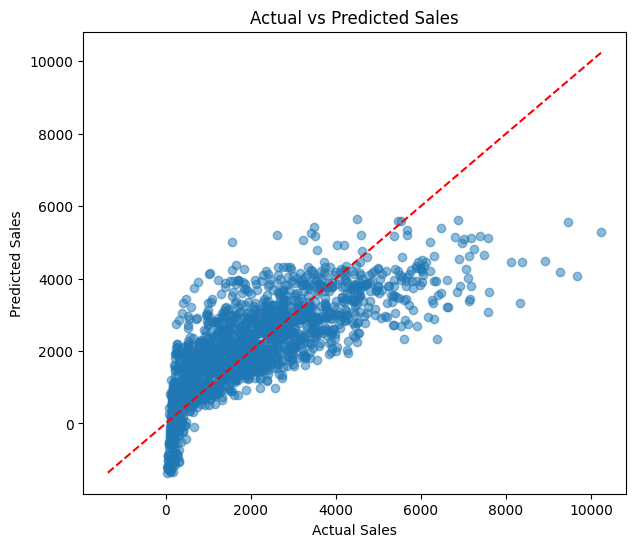

In [50]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], 'r--')
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual vs Predicted Sales')
plt.show()

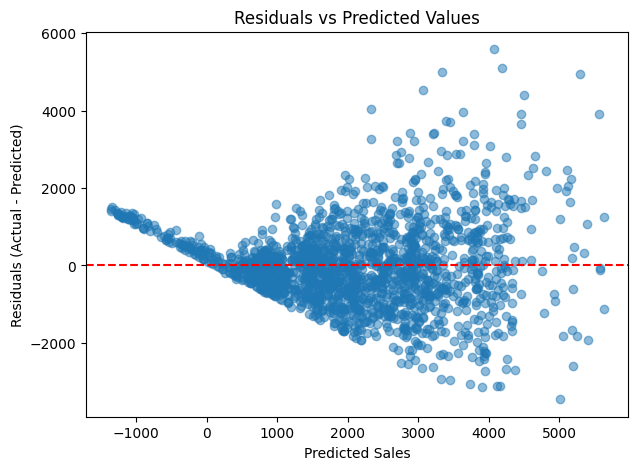

In [51]:
residuals = y_test - y_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted Sales')
plt.ylabel('Residuals (Actual - Predicted)')
plt.title('Residuals vs Predicted Values')
plt.show()

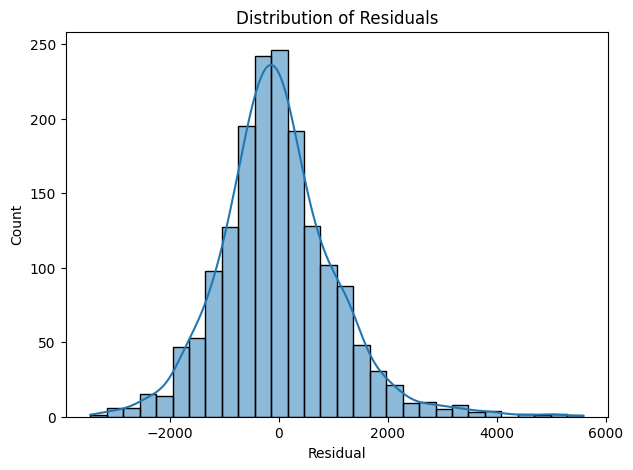

In [52]:
plt.figure(figsize=(7, 5))
sns.histplot(residuals, bins=30, kde=True)
plt.xlabel('Residual')
plt.title('Distribution of Residuals')
plt.show()

In [53]:
results = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': y_pred,
    'Residual': residuals.values
})
display(results.head(10))

,Actual Sales,Predicted Sales,Residual
0,1743.0644,1360.898706,382.165694
1,356.8688,707.295707,-350.426907
2,377.5086,877.403668,-499.895068
3,5778.4782,4229.689822,1548.788378
4,2356.9320,3347.399972,-990.467972
5,865.5400,638.042525,227.497475
6,4613.9940,4753.502405,-139.508405
7,2410.8618,2048.239152,362.622648
8,1948.1308,1393.229078,554.901722
9,1937.4780,2786.420151,-848.942151


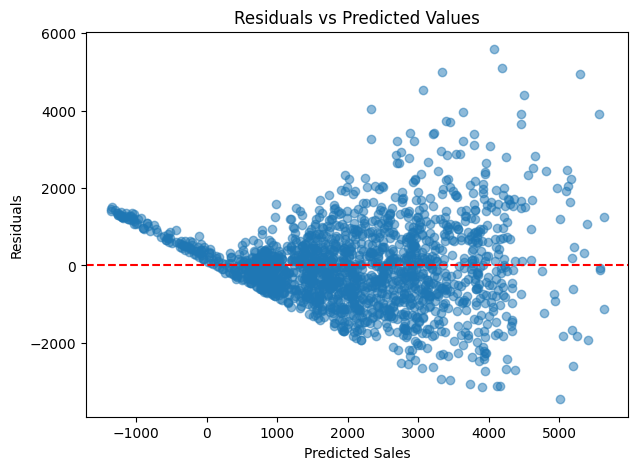

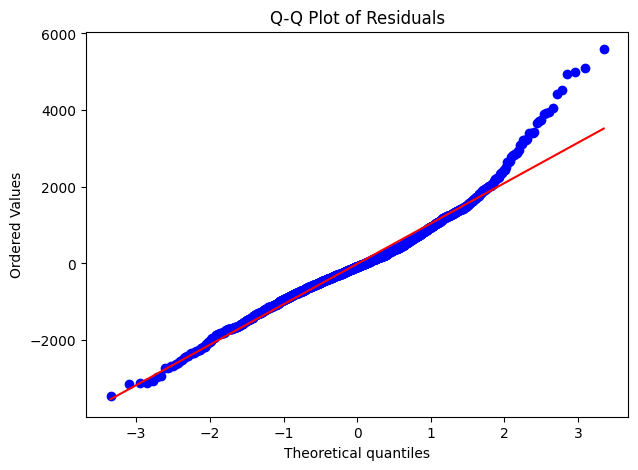

Durbin-Watson Statistic: 1.9995841960328107


In [54]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from statsmodels.stats.stattools import durbin_watson

# Generate predictions using the trained model
y_pred = model.predict(X_test)

# Calculate residuals
residuals = np.array(y_test).ravel() - np.array(y_pred).ravel()

# 1. Linearity and 2. Homoscedasticity
plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values")
plt.show()

# 3. Normality of residuals
plt.figure(figsize=(7, 5))
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Q-Q Plot of Residuals")
plt.show()

# 4. Independence of errors (Durbin-Watson)
dw_stat = durbin_watson(residuals)

print("Durbin-Watson Statistic:", dw_stat)

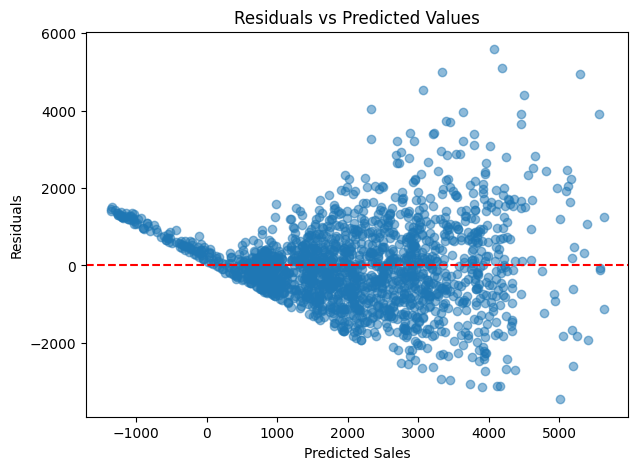

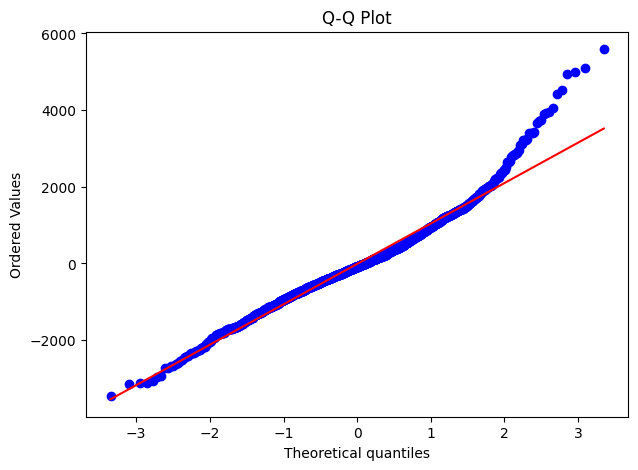

Durbin-Watson Statistic: 1.9995841960328107


In [55]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from statsmodels.stats.stattools import durbin_watson

# Predictions
y_pred = model.predict(X_test)

# Calculate residuals
residuals = np.array(y_test).ravel() - np.array(y_pred).ravel()

# 1. Linearity and Homoscedasticity
plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values")
plt.show()

# 2. Normality - Q-Q Plot
plt.figure(figsize=(7, 5))
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Q-Q Plot")
plt.show()

# 3. Independence - Durbin Watson
dw = durbin_watson(residuals)

print("Durbin-Watson Statistic:", dw)